# Define the train method

In [56]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to("cuda"), y_batch.to("cuda")
            y_pred = model(X_batch)
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=2, factor=0.5, epoch_callback=None):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to("cuda"), y_batch.to("cuda")
            y_pred = model(X_batch)

            #print("Input shape:", X_batch.shape)
            #print("Prediction shape:", y_pred.shape)
            #print("Target shape:", y_batch.shape)

            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss/(index+1):.4f}", end="")
            print(f", {train_metric=:.3f}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"\rEpoch {epoch + 1}/{n_epochs},                      "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.3}, "
              f"valid metric: {history['valid_metrics'][-1]:.3}")
    return history

# Define the denoising autoencoder

In [57]:
import torch.nn as nn

dropout_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(1 * 28 * 28, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
)
dropout_decoder = nn.Sequential(
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28), nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28))
)

dropout_ae = nn.Sequential(dropout_encoder, dropout_decoder).to("cuda")

# Load the MNIST data

In [58]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Convert each image to a PyTorch tensor
transform = transforms.ToTensor()

# Download and load the MNIST training dataset
mnist_train_full = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Split into training and validation sets
train_dataset, valid_dataset = random_split(
    mnist_train_full,
    [55000, 5000],
    generator=torch.Generator().manual_seed(42)
)

from torch.utils.data import Dataset

class AutoencoderDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        x, _ = self.base_dataset[idx]
        return x, x

train_loader = DataLoader(AutoencoderDataset(train_dataset), batch_size=128,
                          shuffle=True)
valid_loader = DataLoader(AutoencoderDataset(valid_dataset), batch_size=128)

# Train

In [59]:
optimizer = torch.optim.NAdam(dropout_ae.parameters(), lr=0.01)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to("cuda")
history = train(dropout_ae, optimizer, mse, rmse, train_loader, valid_loader,
                n_epochs=10)

Epoch 1/10,                      train loss: 0.0374, train metric: 0.193, valid metric: 0.165
Epoch 2/10,                      train loss: 0.0249, train metric: 0.158, valid metric: 0.15
Epoch 3/10,                      train loss: 0.0227, train metric: 0.151, valid metric: 0.138
Epoch 4/10,                      train loss: 0.0216, train metric: 0.147, valid metric: 0.139
Epoch 5/10,                      train loss: 0.0182, train metric: 0.135, valid metric: 0.12
Epoch 6/10,                      train loss: 0.0175, train metric: 0.132, valid metric: 0.12
Epoch 7/10,                      train loss: 0.0171, train metric: 0.131, valid metric: 0.118
Epoch 8/10,                      train loss: 0.0157, train metric: 0.125, valid metric: 0.111
Epoch 9/10,                      train loss: 0.0153, train metric: 0.124, valid metric: 0.109
Epoch 10/10,                      train loss: 0.0151, train metric: 0.123, valid metric: 0.108


# Visualizing the image reconstructions

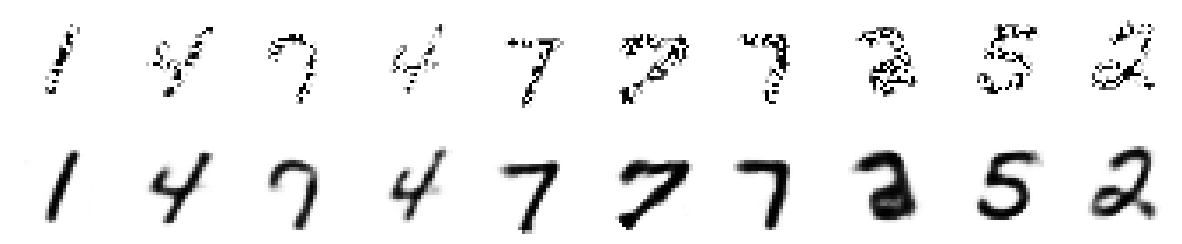

In [60]:
import matplotlib.pyplot as plt

def plot_image(image):
    plt.imshow(image.permute(1, 2, 0).cpu(), cmap="binary")
    plt.axis("off")

def plot_reconstructions(model, images, n_images=10):
    images = images[:n_images]
    with torch.no_grad():
        y_pred = model(images.to("cuda"))
    if isinstance(y_pred, tuple):
        y_pred = y_pred.output
    fig = plt.figure(figsize=(len(images) * 1.5, 3))
    for idx in range(len(images)):
        plt.subplot(2, len(images), 1 + idx)
        plot_image(images[idx])
        plt.subplot(2, len(images), 1 + len(images) + idx)
        plot_image(y_pred[idx])

X_valid = torch.stack([x for x, _ in valid_dataset])

torch.manual_seed(42)
dropout = nn.Dropout(0.5)
plot_reconstructions(dropout_ae, dropout(X_valid))

plt.show()

# Visualize the images (5) that most activate each neuron in the coding layer



In [61]:
with torch.no_grad():
    output_coding_layer = dropout_encoder(X_valid.to("cuda"))

values, indices = torch.topk(output_coding_layer, k=5, dim=0)

import matplotlib.pyplot as plt

def plot_top_images(indices, images, unit_ids=None, cmap="gray"):
    """
    indices:  (k, num_units) tensor of image indices (columns = units)
    images:   array/tensor of shape (N, H, W) or (N, H, W, C) or (N, C, H, W)
    unit_ids: which columns to plot (default: all)
    """
    idx = indices.T.cpu().numpy()            # (num_units, k): one row per unit
    if unit_ids is not None:
        idx = idx[unit_ids]
    n_rows, n_cols = idx.shape

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.8 * n_cols, 1.8 * n_rows),
                             squeeze=False)
    for r in range(n_rows):
        for c in range(n_cols):
            img = images[idx[r, c]]
            if hasattr(img, "cpu"):          # torch tensor -> numpy
                img = img.cpu().numpy()
            if img.ndim == 3 and img.shape[0] in (1, 3):   # (C, H, W) -> (H, W, C)
                img = img.transpose(1, 2, 0)
            if img.ndim == 3 and img.shape[-1] == 1:
                img = img.squeeze(-1)
            axes[r, c].imshow(img, cmap=cmap)
            axes[r, c].axis("off")
        label = unit_ids[r] if unit_ids is not None else r
        axes[r, 0].set_title(f"unit {label}", fontsize=8, loc="left")
    plt.tight_layout()
    plt.show()

plot_top_images(indices, X_valid)


# Build a classification DNN using the autoencoder (with pretraining)

In [62]:
classification_model_with_pretraining = nn.Sequential(dropout_encoder,
                             nn.Linear(128,10)).to("cuda")

for param in classification_model_with_pretraining[0].parameters():
    param.requires_grad = False

# Classification DNN using the autoencoder (without pretraining)

In [63]:
scratch_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(1 * 28 * 28, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
)

classification_model_without_pretraining = nn.Sequential(scratch_encoder,
                                nn.Linear(128,10)).to("cuda")
for param in classification_model_without_pretraining[0].parameters():
    param.requires_grad = False

# Build the loaders for classification

In [64]:
from torch.utils.data import Subset
train_loader = DataLoader(Subset(train_dataset, list(range(500))), batch_size=128,
                          shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=128)

# Train the DNN (one with pretraining)

In [65]:
optimizer = torch.optim.NAdam(classification_model_with_pretraining[1].parameters(), lr=0.01)
xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to("cuda")

history = train(classification_model_with_pretraining, optimizer, xentropy, accuracy, train_loader, valid_loader,
                n_epochs=10)


Epoch 1/10,                      train loss: 2.1117, train metric: 0.324, valid metric: 0.607
Epoch 2/10,                      train loss: 1.0142, train metric: 0.712, valid metric: 0.763
Epoch 3/10,                      train loss: 0.6449, train metric: 0.818, valid metric: 0.832
Epoch 4/10,                      train loss: 0.4571, train metric: 0.884, valid metric: 0.861
Epoch 5/10,                      train loss: 0.3827, train metric: 0.89, valid metric: 0.862
Epoch 6/10,                      train loss: 0.3021, train metric: 0.914, valid metric: 0.867
Epoch 7/10,                      train loss: 0.2746, train metric: 0.918, valid metric: 0.871
Epoch 8/10,                      train loss: 0.2423, train metric: 0.938, valid metric: 0.879
Epoch 9/10,                      train loss: 0.2359, train metric: 0.932, valid metric: 0.88
Epoch 10/10,                      train loss: 0.1984, train metric: 0.946, valid metric: 0.88


# Train the DNN (one without pretraining)

In [66]:
optimizer = torch.optim.NAdam(classification_model_without_pretraining[1].parameters(), lr=0.01)
history = train(classification_model_without_pretraining, optimizer, xentropy, accuracy, train_loader, valid_loader,
                n_epochs=10)

Epoch 1/10,                      train loss: 2.2996, train metric: 0.138, valid metric: 0.161
Epoch 2/10,                      train loss: 2.2732, train metric: 0.168, valid metric: 0.208
Epoch 3/10,                      train loss: 2.2461, train metric: 0.248, valid metric: 0.284
Epoch 4/10,                      train loss: 2.2222, train metric: 0.272, valid metric: 0.344
Epoch 5/10,                      train loss: 2.1988, train metric: 0.302, valid metric: 0.399
Epoch 6/10,                      train loss: 2.1750, train metric: 0.376, valid metric: 0.421
Epoch 7/10,                      train loss: 2.1445, train metric: 0.382, valid metric: 0.453
Epoch 8/10,                      train loss: 2.1238, train metric: 0.398, valid metric: 0.467
Epoch 9/10,                      train loss: 2.1033, train metric: 0.408, valid metric: 0.486
Epoch 10/10,                      train loss: 2.0785, train metric: 0.438, valid metric: 0.499
